# BANKING77: fine-tuning a 0.8B model with Unsloth

So far, the models had to be **told** the task in every prompt: the list of 77 intents alone is about 500 tokens,
and even then `qwen3.5:0.8b` only reached 0.44. Fine-tuning **teaches** the task instead: the model sees labelled
training queries and learns to answer with the right intent. Afterwards the prompt only needs the query.

Setup:

* Model: `Qwen3.5-0.8B` (the same model as `qwen3.5:0.8b` in Ollama), trained with [Unsloth](https://unsloth.ai).
* **LoRA**: the original weights stay frozen; small adapter matrices (rank 16) are added to every linear layer.
  Only 6.4M of the 859M parameters (0.74%) are trained, which fits easily into the 8 GB laptop GPU.
* Training data: 1, 5, 10, 25, 50 or all (about 130) BANKING77 **training** queries per intent, 3 epochs each.
  The loss is computed on the answer (the label) only.
* Evaluation: greedy decoding, on the full test set (3,080 queries) and on the same balanced subset as in the
  other notebooks (385 queries).

Run with `uv run --group finetune python scripts/finetune_banking77.py --train-per-class 1 5 10 25 50 all --epochs 3`
(about 35 minutes on the laptop GPU).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slm import RESULTS_DIR
from slm.data import load_banking77
from slm.evaluation import stratified_subset

RUN_DIR = RESULTS_DIR / "banking77" / "finetune" / "Qwen3.5-0.8B"
SIZES = ["0", "1", "5", "10", "25", "50", "all"]

dataset = load_banking77()
subset = stratified_subset(dataset.test, per_class=5)

summary = pd.read_csv(RUN_DIR / "summary.csv", dtype={"train_per_class": str}).set_index("train_per_class")
summary = summary.loc[[s for s in SIZES if s in summary.index]]
summary["examples_per_intent"] = summary["train_examples"] / len(dataset.labels)


def load_predictions(size):
    records = pd.DataFrame([json.loads(line) for line in
                            (RUN_DIR / f"train-{size}_predictions.jsonl").read_text().splitlines()]).set_index("idx")
    results = dataset.test.join(records)
    results["correct"] = results["prediction"] == results["label"]
    return results


# Prompted models (hand-written prompt with the label list, constrained output; notebook 01), same subset
prompted = {}
for model in ["qwen3.5:0.8b", "qwen3.5:9b", "qwen3.6:35b-a3b"]:
    path = RESULTS_DIR / "banking77" / "structured_no-think" / f"{model.replace(':', '_')}.jsonl"
    records = pd.DataFrame([json.loads(line) for line in path.read_text().splitlines()]).set_index("idx")
    r = subset.join(records[["prediction"]], how="inner")
    prompted[model] = (r["prediction"] == r["label"]).mean()

summary[["train_examples", "accuracy_test", "accuracy_subset", "invalid_rate", "train_loss", "train_time_s"]].round(3)

/home/phth01/PycharmProjects/small-language-models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,train_examples,accuracy_test,accuracy_subset,invalid_rate,train_loss,train_time_s
train_per_class,,,,,,
0,0,0.000,0.000,1.000,NaN,0.000
1,77,0.086,0.078,0.838,2.856,29.307
5,385,0.555,0.543,0.219,1.214,45.661
10,770,0.762,0.743,0.049,0.672,91.204
25,1925,0.864,0.870,0.012,0.348,195.163
50,3826,0.907,0.909,0.005,0.213,392.199
all,10003,0.935,0.930,0.002,0.112,1027.547


## 1. What the model sees

The fine-tuned model gets a one-sentence instruction and the query, and learns to answer with the label.
During training, the label is appended to the prompt; only the label tokens contribute to the loss.

In [2]:
from transformers import AutoTokenizer

from slm.evaluation.classification import LLMClassifier
from slm.finetuning import build_prompt

tokenizer = AutoTokenizer.from_pretrained("unsloth/Qwen3.5-0.8B")
example = dataset.train.iloc[0]
prompt = build_prompt(tokenizer, example["text"])
print(prompt + example["label"] + tokenizer.eos_token)

# Prompt length: fine-tuned model vs. the hand-written prompt with the label list
lengths = [len(tokenizer(build_prompt(tokenizer, text), add_special_tokens=False)["input_ids"]) for text in subset["text"]]
print(f"\nprompt tokens per query, fine-tuned model: {np.mean(lengths):.0f} (hand-written prompt with label list: 522)")

<|im_start|>system
Classify the intent of the customer message sent to a bank. Answer with the intent label only.<|im_end|>
<|im_start|>user
I am still waiting on my card?<|im_end|>
<|im_start|>assistant
<think>

</think>

card_arrival<|im_end|>

prompt tokens per query, fine-tuned model: 50 (hand-written prompt with label list: 522)


## 2. How many training examples are needed?

Accuracy on the balanced subset per number of training examples per intent (log scale). The dashed lines are the
prompted models from notebook 01 on the same queries. Without training (0 examples), the model does not know the
label names and never answers with a valid label.

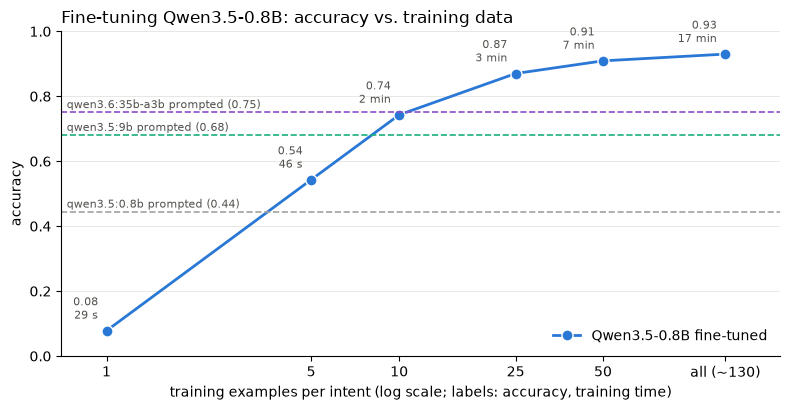

In [3]:
trained = summary[summary["train_examples"] > 0]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(trained["examples_per_intent"], trained["accuracy_subset"], color="#2a78d6", linewidth=2, marker="o",
        markersize=8, markeredgecolor="white", label="Qwen3.5-0.8B fine-tuned")
for _, row in trained.iterrows():
    minutes = row["train_time_s"] / 60
    ax.annotate(f"{row['accuracy_subset']:.2f}\n" + (f"{minutes:.0f} min" if minutes >= 1 else f"{row['train_time_s']:.0f} s"),
                (row["examples_per_intent"], row["accuracy_subset"]), textcoords="offset points",
                xytext=(-6, 6), ha="right", va="bottom", fontsize=8, color="#52514e")
for (model, accuracy), color in zip(prompted.items(), ["#a3a29d", "#1baf7a", "#8a4fc7"]):
    ax.axhline(accuracy, color=color, linestyle="--", linewidth=1.2)
    ax.annotate(f"{model} prompted ({accuracy:.2f})", (0.0, accuracy), xycoords=("axes fraction", "data"),
                xytext=(4, 3), textcoords="offset points", ha="left", fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_xticks(trained["examples_per_intent"],
              [f"all (~{x:.0f})" if size == "all" else size for size, x in trained["examples_per_intent"].items()])
ax.set_xlim(0.7, 200)
ax.minorticks_off()
ax.set_ylim(0, 1)
ax.set_xlabel("training examples per intent (log scale; labels: accuracy, training time)")
ax.set_ylabel("accuracy")
ax.set_title("Fine-tuning Qwen3.5-0.8B: accuracy vs. training data", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()

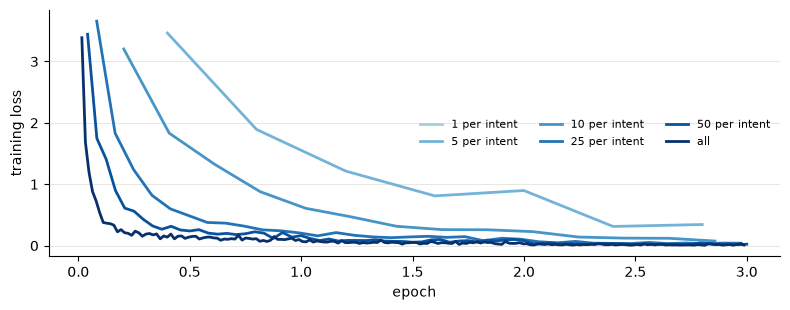

In [4]:
# Training loss per run (logged every 10 steps; the run with 1 example per intent has only 15 steps)
fig, ax = plt.subplots(figsize=(8, 3.2))
colors = plt.cm.Blues(np.linspace(0.35, 1, len(trained)))
for (size, row), color in zip(trained.iterrows(), colors):
    log = [entry for entry in json.loads((RUN_DIR / f"train-{size}_log.json").read_text()) if "loss" in entry]
    if log:
        ax.plot([e["epoch"] for e in log], [e["loss"] for e in log], color=color, linewidth=2, label="all" if size == "all" else f"{size} per intent")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss")
ax.legend(frameon=False, ncol=3, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
plt.tight_layout()

## 3. What is still wrong?

The most frequent confusions of the model trained on the full training set (full test set).

In [5]:
best = load_predictions("all")
print(f"accuracy {best['correct'].mean():.3f}, invalid answers {(best['prediction'] == '<invalid>').mean():.3%}\n")
errors = best[~best["correct"]]
errors.groupby(["label", "prediction"]).size().sort_values(ascending=False).head(10).rename("count").to_frame()

accuracy 0.935, invalid answers 0.162%



,,count
label,prediction,
declined_transfer,declined_card_payment,5
balance_not_updated_after_bank_transfer,transfer_timing,4
card_delivery_estimate,card_arrival,4
card_payment_not_recognised,compromised_card,4
wrong_exchange_rate_for_cash_withdrawal,card_payment_wrong_exchange_rate,4
balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,3
exchange_charge,exchange_rate,3
compromised_card,lost_or_stolen_card,3
card_arrival,card_delivery_estimate,3


In [6]:
# Per intent: the hardest intents for the fine-tuned model vs. the prompted 0.8b model on the same subset
records = pd.DataFrame([json.loads(line) for line in (RESULTS_DIR / "banking77" / "structured_no-think" /
                                                      "qwen3.5_0.8b.jsonl").read_text().splitlines()]).set_index("idx")
compare = subset.join(records[["prediction"]].rename(columns={"prediction": "prompted"}), how="inner")
compare["fine-tuned"] = best.loc[compare.index, "prediction"]
per_intent = pd.DataFrame({
    "prompted 0.8b": (compare["prompted"] == compare["label"]).groupby(compare["label"]).mean(),
    "fine-tuned 0.8b": (compare["fine-tuned"] == compare["label"]).groupby(compare["label"]).mean(),
})
per_intent.sort_values("fine-tuned 0.8b").head(10)

,prompted 0.8b,fine-tuned 0.8b
label,,
declined_transfer,0.2,0.4
balance_not_updated_after_bank_transfer,0.0,0.6
unable_to_verify_identity,0.2,0.6
balance_not_updated_after_cheque_or_cash_deposit,0.2,0.8
card_arrival,0.0,0.8
card_delivery_estimate,0.6,0.8
change_pin,0.8,0.8
automatic_top_up,0.6,0.8
compromised_card,0.0,0.8


## 4. Try it

Loads the adapter trained on the full training set (needs the GPU and the `finetune` dependency group).

In [7]:
import contextlib
import io
import warnings

warnings.filterwarnings("ignore")
import transformers

transformers.logging.set_verbosity_error()  # hides the note about the missing causal_conv1d kernel
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):  # hide loading logs
    from slm.finetuning import load_model, predict
    from peft import PeftModel

    model, tokenizer = load_model("unsloth/Qwen3.5-0.8B", lora_rank=None)
    model = PeftModel.from_pretrained(model, str(RUN_DIR / "train-all_adapter"))
queries = [
    "How do I locate my card?",
    "I was charged twice for the same coffee",
    "Can I get my money back for this order?",
    "my app says my identity can't be verified",
]
with contextlib.redirect_stderr(io.StringIO()):
    predictions, raw, seconds = predict(model, tokenizer, queries, dataset.labels)
for query, prediction in zip(queries, predictions):
    print(f"{prediction:<35} {query}")

lost_or_stolen_card                 How do I locate my card?
transaction_charged_twice           I was charged twice for the same coffee
request_refund                      Can I get my money back for this order?
unable_to_verify_identity           my app says my identity can't be verified


## Takeaways

* **Fine-tuning beats prompting by a wide margin.** With 10 examples per intent and 2 minutes of training, the
  0.8B model reaches 0.74 on the subset, as good as the prompted `qwen3.6:35b-a3b` (0.75) and better than the prompted
  `9b` (0.68). With 25 examples per intent (3 minutes) it reaches 0.87, with the full training set 0.93
  (0.935 on the full test set). The same model with the hand-written prompt: 0.44.
* **Few examples go a long way, but not one**: 1 example per intent is not enough (0.08, mostly invalid answers);
  from 5 examples per intent (0.54) the model beats its prompted version, and the curve flattens after about 50.
* **The prompt shrinks**: 50 instead of 522 tokens per query, because the label list is no longer needed. The
  labels are now in the weights.
* **Cheap**: LoRA trains 0.74% of the parameters; everything ran on an 8 GB laptop GPU in minutes. The adapter is
  44 MB.
* **The remaining errors are the near-duplicate intents** that confused every model in this talk
  (`declined_transfer` vs. `declined_card_payment`, `card_arrival` vs. `card_delivery_estimate`).

**Caveats**: the fine-tuned model has seen thousands of labelled queries from the same distribution as the test set;
the prompted models saw none (or 16 in DSPy's few-shot). Fine-tuning needs labelled data and has to be repeated when
the intents change, while a prompt is edited in seconds. The fine-tuned model runs in Hugging Face, not Ollama, so its
speed is not comparable with the other notebooks.